# Challenge 2: Naive Bayes

Predict `Revenue` (did the visit end in a purchase?) with scikit-learn's `GaussianNB`.

1. Load the data and make the same split as `challenge2_validation_split.ipynb` (same seed, so the same rows and folds).
2. Look at the data.
3. Prepare the features. Naive Bayes gets different inputs from the other models.
4. Score a baseline and default versions of the model.
5. Tune the number of features kept and the variance smoothing with grid search on the 5 folds.
6. Pick the decision threshold that gives the best F1.
7. Evaluation charts: model comparison, tuning, over/underfitting, ROC and precision-recall curves, threshold, confusion matrices, probabilities, calibration, learning curve, and feature importance.

The 20% hold-out is **not** used here. It gets scored once, after the team compares all models.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (make_scorer, f1_score, precision_score, recall_score, confusion_matrix,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

RANDOM_STATE = 42
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.0


In [2]:
# chart style used by every figure below (same as the other team notebooks)
NAVY, ORANGE, TEAL, RED, GRAY = "#1f3b73", "#f28e2b", "#2a9d8f", "#d1495b", "#9aa0a6"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.frameon": False,
    "font.size": 10,
})
MODEL_COLOR = ORANGE

In [3]:
MODEL_LABEL = "Naive Bayes"

## Load and split

Same code and seed as `challenge2_validation_split.ipynb`, so these are the same training rows, hold-out rows and folds as every other model in the team.

In [4]:
train = pd.read_csv("challenge2_train.csv")

def to_01(col):
    """Turn True/False (bool or text) into 1/0."""
    if col.dtype == bool:
        return col.astype(int)
    return col.astype(str).str.strip().str.lower().map({"true": 1, "false": 0})

y = to_01(train["Revenue"])
X = train.drop(columns=["ID", "Revenue"]).copy()
X["Weekend"] = to_01(X["Weekend"])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
BUYER_SHARE = y_train.mean()

print(f"Training rows: {len(X_train):,} ({BUYER_SHARE:.1%} buyers)")
print(f"Hold-out rows: {len(X_val):,} (not used in this notebook)")

Training rows: 7,397 (15.5% buyers)
Hold-out rows: 1,850 (not used in this notebook)


## Look at the data

The split notebook already checked types and missing values (none). Three things matter here:

1. **Skew.** Most count and duration columns are near zero with a few huge values. `GaussianNB` models each feature as a bell curve for each class, so a long tail is a poor fit.
2. **Overlap between features.** Naive Bayes treats features as independent. If two columns say the same thing, it counts that evidence twice. This is the main thing to watch in the tuning below.
3. **What separates buyers.** Which columns have a visible link to purchasing.

Column groups used throughout:
- **Long-tailed** (counts, durations, `PageValues`): `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `PageValues`.
- **Rates**: `BounceRates`, `ExitRates`, `SpecialDay`.
- **Category codes**: `Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`.
- **Binary**: `Weekend`.

In [5]:
log_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "PageValues"]
rate_cols = ["BounceRates", "ExitRates", "SpecialDay"]
cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
bin_cols = ["Weekend"]
num_cols = log_cols + rate_cols

assert set(num_cols + cat_cols + bin_cols) == set(X.columns)

skew = pd.DataFrame({
    "skew (raw)": X_train[log_cols].skew(),
    "skew (after log(1+x))": np.log1p(X_train[log_cols]).skew(),
}).round(2)
skew

,skew (raw),skew (after log(1+x))
Administrative,2.01,0.56
Administrative_Duration,5.52,0.25
Informational,3.75,2.05
Informational_Duration,7.33,1.94
ProductRelated,4.28,-0.05
ProductRelated_Duration,8.35,-1.42
PageValues,6.35,1.81


Skew above 1 or 2 means a long right tail. `log(1 + x)` cuts the skew sharply for every column (for example from 8.4 to -1.4 for `ProductRelated_Duration`, which overshoots slightly to a mild left skew). Some columns stay skewed (`Informational`, `PageValues`) because most visits are exactly zero, and a log cannot remove a spike at zero.

The chart on the left shows how strongly the 10 numeric features move together (after the log). The middle and right charts show the buyer share for the groups that matter most.

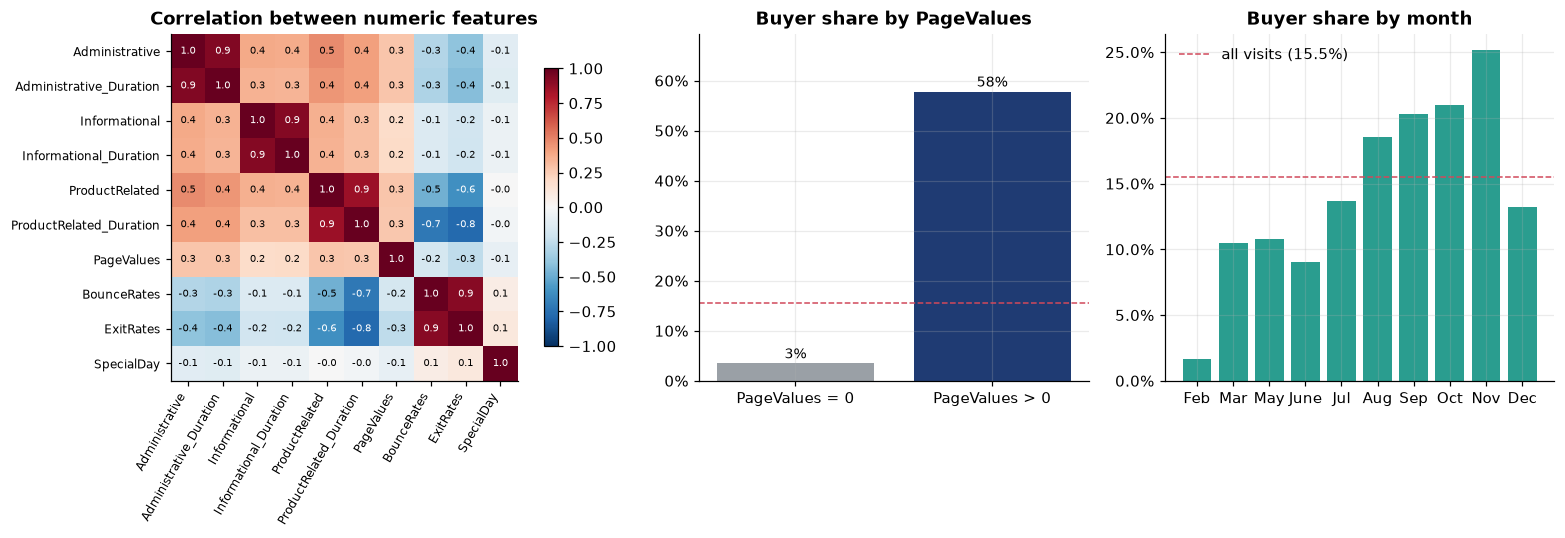

Administrative           Administrative_Duration    0.93
Informational            Informational_Duration     0.92
BounceRates              ExitRates                  0.91
ProductRelated           ProductRelated_Duration    0.86
ProductRelated_Duration  ExitRates                  0.78


In [6]:
Z = X_train[num_cols].copy()
Z[log_cols] = np.log1p(Z[log_cols])
corr = Z.corr()

month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
assert set(X_train["Month"]) <= set(month_order)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.35, 1, 1]})

im = ax1.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax1.set_xticks(range(len(num_cols)), num_cols, rotation=60, ha="right", fontsize=8)
ax1.set_yticks(range(len(num_cols)), num_cols, fontsize=8)
ax1.grid(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax1.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                 color="white" if abs(corr.values[i, j]) > 0.6 else "black")
ax1.set_title("Correlation between numeric features")
fig.colorbar(im, ax=ax1, shrink=0.8)

has_pv = X_train["PageValues"].gt(0).map({False: "PageValues = 0", True: "PageValues > 0"})
rate_pv = y_train.groupby(has_pv).mean()
bars = ax2.bar(rate_pv.index, rate_pv.values, color=[GRAY, NAVY])
for b, v in zip(bars, rate_pv.values):
    ax2.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
ax2.axhline(BUYER_SHARE, color=RED, linestyle="--", linewidth=1)
ax2.set_ylim(0, max(rate_pv.values) * 1.2)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set_title("Buyer share by PageValues")

rate_month = y_train.groupby(X_train["Month"]).mean().reindex(month_order).dropna()
ax3.bar(rate_month.index, rate_month.values, color=TEAL)
ax3.axhline(BUYER_SHARE, color=RED, linestyle="--", linewidth=1, label=f"all visits ({BUYER_SHARE:.1%})")
ax3.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax3.set_title("Buyer share by month")
ax3.legend()
plt.tight_layout()
plt.show()

print(corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().abs().sort_values(ascending=False).head(5).round(2).to_string())

What this tells us:

- **`PageValues` is the strongest signal.** About 58% of visits with a non-zero `PageValues` end in a purchase, against 3% of visits with zero.
- **Several features overlap.** Each page count is tied to its duration (`Administrative` and `Administrative_Duration` correlate at 0.93, the other two pairs at 0.92 and 0.86), and `BounceRates` and `ExitRates` correlate at 0.91.
- **Season matters.** Buyer share runs from under 2% in February to about 25% in November, so `Month` stays in as a category.

## Prepare the features

`GaussianNB` models each feature as a bell curve per class, so it gets only the **10 numeric columns**:

- **Long-tailed columns**: `log(1 + x)` then `StandardScaler`.
- **Rates** (`BounceRates`, `ExitRates`, `SpecialDay`): scaled.

One-hot 0/1 columns are not bell-shaped, so the category codes and `Weekend` are left out. The comparison table below shows what happens when they are included.

Everything sits inside a pipeline, so scalers (and later the feature selection) are fitted on each fold's training rows only.

In [7]:
def log1p_tf():
    return FunctionTransformer(np.log1p, feature_names_out="one-to-one")

# numeric columns only
prep_nb = ColumnTransformer([
    ("log", Pipeline([("log1p", log1p_tf()), ("scale", StandardScaler())]), log_cols),
    ("rate", StandardScaler(), rate_cols),
])

# with the one-hot columns too (only used to show why they are left out)
prep_nb_all = ColumnTransformer([
    ("log", Pipeline([("log1p", log1p_tf()), ("scale", StandardScaler())]), log_cols),
    ("rate", StandardScaler(), rate_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("bin", "passthrough", bin_cols),
])

print("Inputs, numeric only:", prep_nb.fit_transform(X_train).shape[1])
print("Inputs, with one-hot columns:", prep_nb_all.fit_transform(X_train).shape[1])

Inputs, numeric only: 10
Inputs, with one-hot columns: 72


## How models are scored

Only 15.5% of visits are purchases, so accuracy is misleading. The main score is **F1** (balances catching buyers against false alarms). Also reported:

- **ROC-AUC** and **PR-AUC**: how well the model ranks buyers above non-buyers, before any threshold is picked.
- **Recall**: share of real buyers caught. **Precision**: share of predicted buyers who really bought.
- **Train F1 and the gap**: a big gap between training and CV F1 means overfitting.

Same metrics, folds and function as the neural network notebook, so the tables line up across the team.

In [8]:
scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "accuracy": "accuracy",
}

def evaluate(name, pipe):
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
        row[f"{m} std"] = res[f"test_{m}"].std()
    row["train f1"] = res["train_f1"].mean()
    row["f1 gap"] = row["train f1"] - row["f1"]
    return row

SHOW = ["f1", "roc_auc", "pr_auc", "recall", "precision", "accuracy", "train f1", "f1 gap"]

In [9]:
N_BASE = "Baseline (always 'no purchase')"
N_ALL = "Naive Bayes, default + one-hot columns"
N_DEF = "Naive Bayes, default"
N_TUNED = "Naive Bayes, tuned"
PLOT_MODELS = [N_BASE, N_ALL, N_DEF, N_TUNED]

results = [
    evaluate(N_BASE, Pipeline([("prep", prep_nb), ("model", DummyClassifier(strategy="most_frequent"))])),
    evaluate(N_ALL, Pipeline([("prep", prep_nb_all), ("model", GaussianNB())])),
    evaluate(N_DEF, Pipeline([("prep", prep_nb), ("model", GaussianNB())])),
]
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"Naive Bayes, default + one-hot columns",0.299,0.698,0.245,0.986,0.176,0.283,0.300,0.001
"Naive Bayes, default",0.499,0.872,0.582,0.868,0.350,0.729,0.499,0.000


Reading the default scores (F1 here uses the default 0.5 cut-off, which is fixed further down):

- With the one-hot columns the model is far worse (ROC-AUC 0.70, F1 0.30). A 0/1 column is not a bell curve, and the 60-odd dummy columns swamp the numeric evidence. They stay out.
- With the 10 numeric columns it ranks visits reasonably (ROC-AUC 0.87) but flags far too many as buyers: recall is high and precision is low. The tuning below checks whether the overlapping features are the reason.

## Tune the model

Naive Bayes has almost nothing to tune on its own, so the search covers the two things that change what it sees:

- **`k`** (`SelectKBest` with the ANOVA F-score): keep only the `k` numeric features most related to `Revenue`. Fewer features means less double-counting of overlapping columns. `k = 10` is all of them. Selection is refitted inside every fold.
- **`var_smoothing`**: a floor added to every feature's variance. It stops a feature that is almost constant in one class from producing extreme probabilities.

Ranked by **ROC-AUC**, not F1, for the same reason as the neural network notebook: F1 depends on the 0.5 cut-off, which is fixed further down.

In [10]:
nb_pipe = Pipeline([("prep", prep_nb), ("select", SelectKBest(f_classif)), ("model", GaussianNB())])

param_grid = {
    "select__k": [2, 3, 4, 5, 6, 8, 10],
    "model__var_smoothing": [1e-9, 1e-3, 1e-2, 0.1, 0.3, 1.0, 3.0],
}

search = GridSearchCV(nb_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)

best_params = {"k": search.best_params_["select__k"],
               "var_smoothing": search.best_params_["model__var_smoothing"]}
print("Best settings:", best_params)
print(f"Best CV ROC-AUC: {search.best_score_:.4f}")

Best settings: {'k': 3, 'var_smoothing': 0.1}
Best CV ROC-AUC: 0.9004


In [11]:
grid = pd.DataFrame(search.cv_results_)
grid["k"] = grid["param_select__k"].astype(int)
grid["var_smoothing"] = grid["param_model__var_smoothing"].astype(float)

grid.sort_values("rank_test_score").head(8)[
    ["k", "var_smoothing", "mean_test_score", "std_test_score", "mean_train_score"]
].rename(columns={"mean_test_score": "CV ROC-AUC", "std_test_score": "CV std", "mean_train_score": "train ROC-AUC"}).round(4).reset_index(drop=True)

,k,var_smoothing,CV ROC-AUC,CV std,train ROC-AUC
0,3,0.100,0.9004,0.0208,0.9006
1,3,0.300,0.9002,0.0206,0.9002
2,3,0.010,0.8999,0.0212,0.9003
3,3,0.001,0.8997,0.0216,0.9002
4,3,0.000,0.8996,0.0216,0.9002
5,3,1.000,0.8993,0.0205,0.8993
6,3,3.000,0.8987,0.0204,0.8987
7,4,0.100,0.8982,0.0198,0.8983


In [12]:
best_pipe = Pipeline([("prep", prep_nb),
                      ("select", SelectKBest(f_classif, k=best_params["k"])),
                      ("model", GaussianNB(var_smoothing=best_params["var_smoothing"]))])

results.append(evaluate(N_TUNED, best_pipe))
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"Naive Bayes, default + one-hot columns",0.299,0.698,0.245,0.986,0.176,0.283,0.300,0.001
"Naive Bayes, default",0.499,0.872,0.582,0.868,0.350,0.729,0.499,0.000
"Naive Bayes, tuned",0.680,0.900,0.675,0.760,0.615,0.889,0.680,0.001


In [13]:
# which numeric features the tuned model keeps (fitted on all training rows)
nb_fit = clone(best_pipe).fit(X_train, y_train)
kept = np.array(num_cols)[nb_fit.named_steps["select"].get_support()]
print(f"Naive Bayes keeps {len(kept)} of {len(num_cols)} features:", ", ".join(kept))

Naive Bayes keeps 3 of 10 features: ProductRelated, PageValues, ExitRates


## Out-of-fold predictions

Every training row gets a purchase probability from a model that did **not** train on it: for each of the 5 folds, train on the other 4 and predict that fold. All charts below and the threshold choice use these predictions, never the hold-out.

In [14]:
oof_proba = np.zeros(len(y_train))
fold_id = np.zeros(len(y_train), dtype=int)

for k, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
    m = clone(best_pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
    oof_proba[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    fold_id[va] = k

y_true = y_train.to_numpy()
print(f"Out-of-fold ROC-AUC: {roc_auc_score(y_true, oof_proba):.3f}")
print(f"Out-of-fold PR-AUC:  {average_precision_score(y_true, oof_proba):.3f}")

Out-of-fold ROC-AUC: 0.900
Out-of-fold PR-AUC:  0.668


## Pick the decision threshold

The model outputs a probability of purchase. By default anything at 0.5 or above counts as "buyer". With only 15.5% buyers, many real buyers sit below 0.5, so a different cut-off can give a better F1. Every threshold from 0.05 to 0.95 is tried on the out-of-fold predictions and the best F1 is kept.

The tuned threshold is picked and scored on the same predictions, so its F1 is slightly optimistic. The hold-out score at the end will be the honest number.

In [15]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame({
    "threshold": thresholds,
    "f1": [f1_score(y_true, oof_proba >= t) for t in thresholds],
    "precision": [precision_score(y_true, oof_proba >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_true, oof_proba >= t) for t in thresholds],
})
best_threshold = float(curve.loc[curve["f1"].idxmax(), "threshold"])

def scores_at(t):
    pred = oof_proba >= t
    return {"threshold": t, "f1": f1_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "accuracy": (pred == y_true).mean()}

pd.DataFrame([scores_at(0.5), scores_at(best_threshold)], index=["default", "tuned"]).round(3)

,threshold,f1,precision,recall,accuracy
default,0.5,0.679,0.614,0.760,0.889
tuned,0.3,0.686,0.601,0.801,0.887


---
# Evaluation charts

### 1. Model comparison

Accuracy (far right) is the trap: the baseline that never predicts a purchase already scores about 85%. The other scores show the real difference. Error bars are the spread across the 5 folds. F1, recall and precision use the default 0.5 cut-off here. Section 5 shows what the tuned cut-off adds.

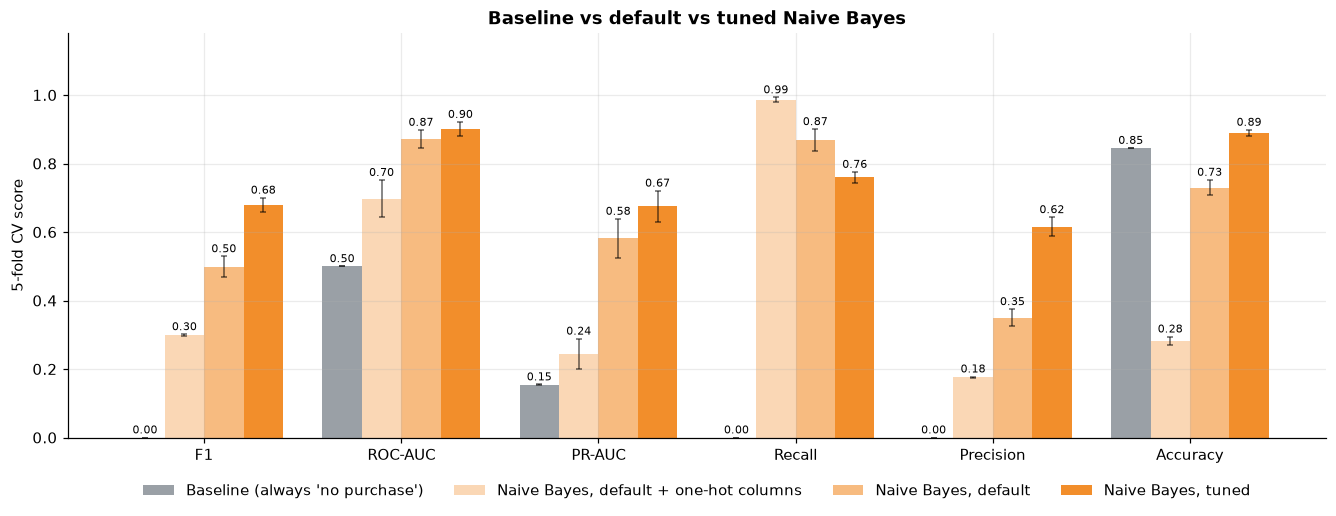

In [16]:
res = pd.DataFrame(results).set_index("model")
metrics = ["f1", "roc_auc", "pr_auc", "recall", "precision", "accuracy"]
labels = ["F1", "ROC-AUC", "PR-AUC", "Recall", "Precision", "Accuracy"]
alphas = [1.0, 0.35, 0.6, 1.0]
colors = [GRAY, MODEL_COLOR, MODEL_COLOR, MODEL_COLOR]

fig, ax = plt.subplots(figsize=(12.5, 4.8))
x = np.arange(len(metrics))
w = 0.2
for i, (name, row) in enumerate(res.loc[PLOT_MODELS].iterrows()):
    vals = [row[m] for m in metrics]
    errs = [row[f"{m} std"] for m in metrics]
    bars = ax.bar(x + (i - 1.5) * w, vals, w, yerr=errs, capsize=2, color=colors[i], alpha=alphas[i], label=name,
                  error_kw={"elinewidth": 1, "alpha": 0.6})
    for b, v, e in zip(bars, vals, errs):
        ax.text(b.get_x() + b.get_width() / 2, v + e + 0.012, f"{v:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.18)
ax.set_ylabel("5-fold CV score")
ax.set_title("Baseline vs default vs tuned Naive Bayes")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
plt.tight_layout()
plt.show()

### 2. Tuning results

Each cell is the CV ROC-AUC for one number of features kept (`k`) and one `var_smoothing`. Dark is better. The black box is the setting chosen. The score depends almost entirely on `k`; `var_smoothing` barely changes it.

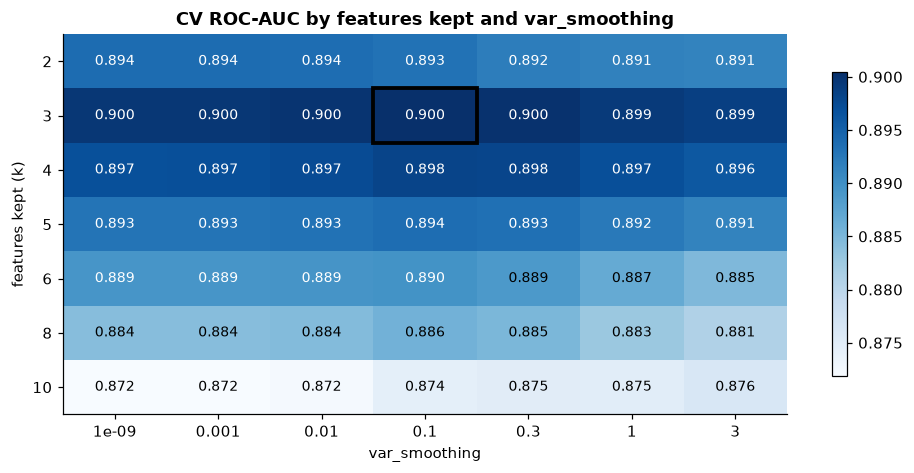

In [17]:
heat = grid.pivot_table(index="k", columns="var_smoothing", values="mean_test_score")
bi = list(heat.index).index(best_params["k"])
bj = list(heat.columns).index(best_params["var_smoothing"])

fig, ax = plt.subplots(figsize=(9, 4.4))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(heat.shape[1]), [f"{v:g}" for v in heat.columns])
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
lo, hi = np.nanmin(heat.values), np.nanmax(heat.values)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="white" if v > lo + 0.6 * (hi - lo) else "black")
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2.5))
ax.set_xlabel("var_smoothing")
ax.set_ylabel("features kept (k)")
ax.set_title("CV ROC-AUC by features kept and var_smoothing")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

### 3. Underfitting vs overfitting across `k`

Training vs CV ROC-AUC while `k` changes and `var_smoothing` stays at its chosen value. The two lines sit on top of each other and fall together once more than 3 features are kept. That is not overfitting. It is the independence assumption failing: every extra overlapping feature adds evidence that is counted twice, which hurts on training rows as much as on unseen ones. With only 2 features the model is slightly too simple. The shaded band (spread across folds) is wider than the differences between neighbouring settings.

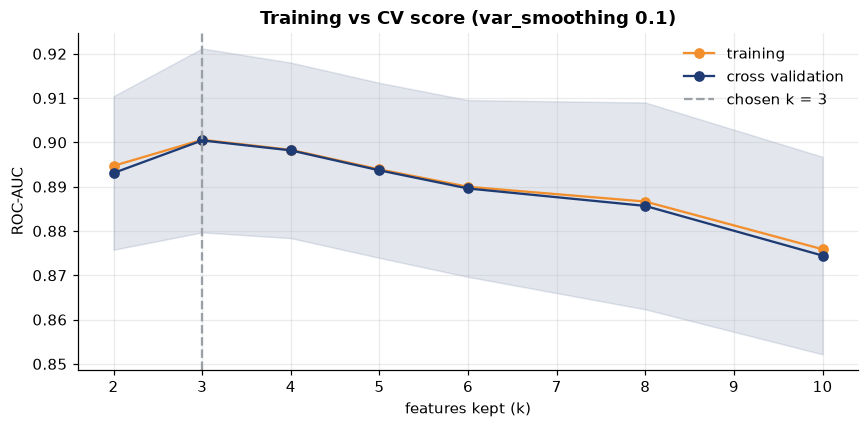

In [18]:
sub = grid[grid["var_smoothing"] == best_params["var_smoothing"]].sort_values("k")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sub["k"], sub["mean_train_score"], "o-", color=ORANGE, label="training")
ax.plot(sub["k"], sub["mean_test_score"], "o-", color=NAVY, label="cross validation")
ax.fill_between(sub["k"], sub["mean_test_score"] - sub["std_test_score"],
                sub["mean_test_score"] + sub["std_test_score"], color=NAVY, alpha=0.12)
ax.axvline(best_params["k"], color=GRAY, linestyle="--", label=f"chosen k = {best_params['k']}")
ax.set_xlabel("features kept (k)")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"Training vs CV score (var_smoothing {best_params['var_smoothing']:g})")
ax.legend()
plt.tight_layout()
plt.show()

### 4. ROC and precision-recall curves

Thin lines are the 5 folds, the thick line is all out-of-fold predictions together. The dot is the chosen threshold.

- **ROC**: the dashed diagonal is random guessing.
- **Precision-recall**: more useful when buyers are rare. The dashed line is the 15.5% buyer share, which is what random guessing gets.

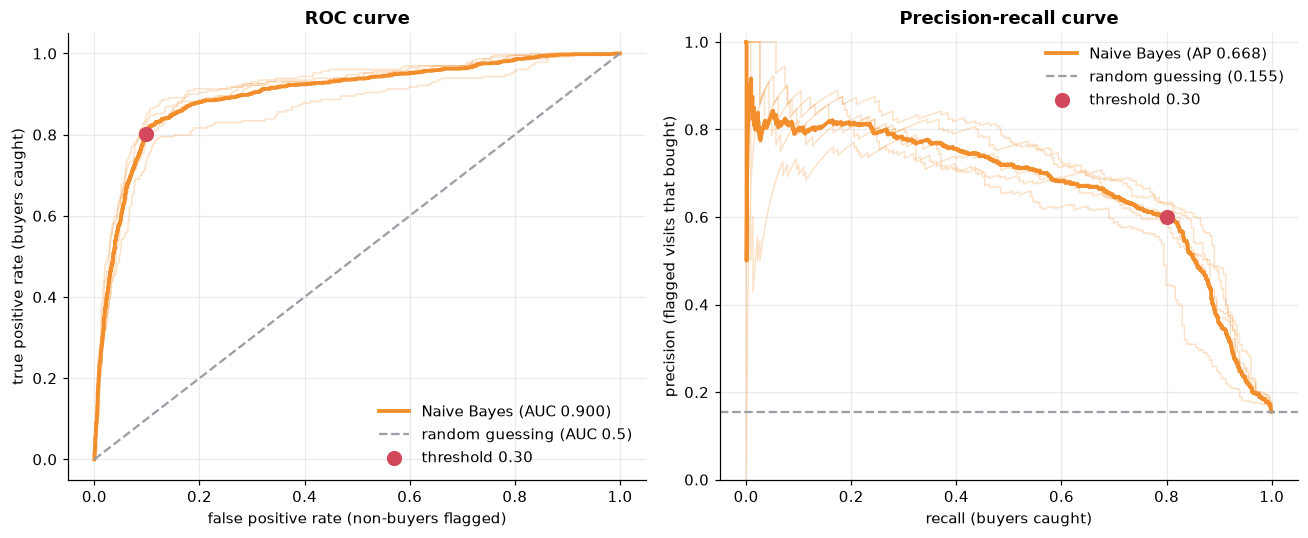

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
pred_best = oof_proba >= best_threshold
tpr_pt = recall_score(y_true, pred_best)
fpr_pt = ((pred_best == 1) & (y_true == 0)).sum() / (y_true == 0).sum()
prec_pt = precision_score(y_true, pred_best)

for k in range(1, 6):
    m = fold_id == k
    fpr, tpr, _ = roc_curve(y_true[m], oof_proba[m])
    ax1.plot(fpr, tpr, color=MODEL_COLOR, alpha=0.25, linewidth=1)
    p, r, _ = precision_recall_curve(y_true[m], oof_proba[m])
    ax2.plot(r, p, color=MODEL_COLOR, alpha=0.25, linewidth=1)

fpr, tpr, _ = roc_curve(y_true, oof_proba)
ax1.plot(fpr, tpr, color=MODEL_COLOR, linewidth=2.5, label=f"{MODEL_LABEL} (AUC {roc_auc_score(y_true, oof_proba):.3f})")
ax1.plot([0, 1], [0, 1], "--", color=GRAY, label="random guessing (AUC 0.5)")
ax1.scatter([fpr_pt], [tpr_pt], s=80, color=RED, zorder=5, label=f"threshold {best_threshold:.2f}")
ax1.set_xlabel("false positive rate (non-buyers flagged)")
ax1.set_ylabel("true positive rate (buyers caught)")
ax1.set_title("ROC curve")
ax1.legend(loc="lower right")

p, r, _ = precision_recall_curve(y_true, oof_proba)
ax2.plot(r, p, color=MODEL_COLOR, linewidth=2.5, label=f"{MODEL_LABEL} (AP {average_precision_score(y_true, oof_proba):.3f})")
ax2.axhline(BUYER_SHARE, linestyle="--", color=GRAY, label=f"random guessing ({BUYER_SHARE:.3f})")
ax2.scatter([tpr_pt], [prec_pt], s=80, color=RED, zorder=5, label=f"threshold {best_threshold:.2f}")
ax2.set_xlabel("recall (buyers caught)")
ax2.set_ylabel("precision (flagged visits that bought)")
ax2.set_ylim(0, 1.02)
ax2.set_title("Precision-recall curve")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 5. Choosing the threshold

Lowering the threshold catches more buyers (recall up) but flags more non-buyers (precision down). F1 balances the two and peaks at the chosen threshold.

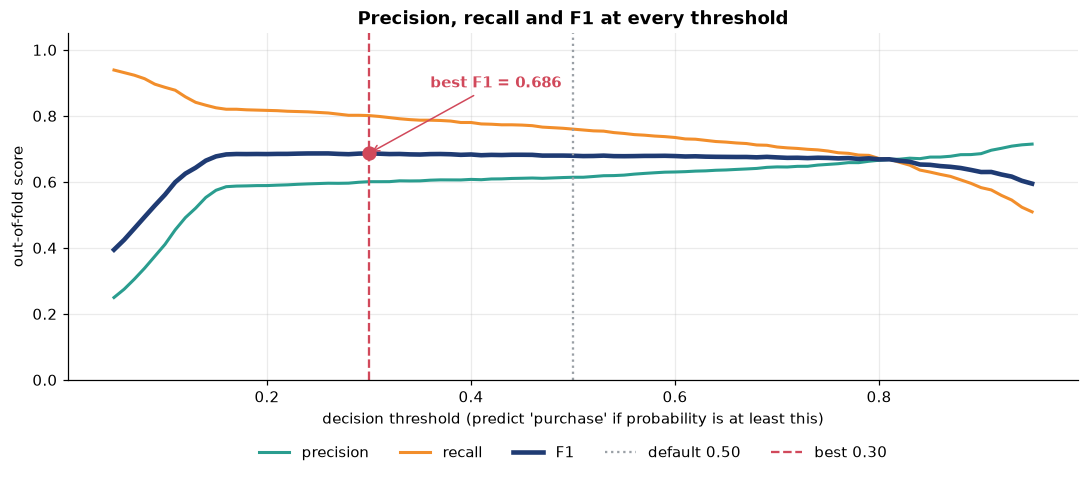

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curve["threshold"], curve["precision"], color=TEAL, linewidth=2, label="precision")
ax.plot(curve["threshold"], curve["recall"], color=ORANGE, linewidth=2, label="recall")
ax.plot(curve["threshold"], curve["f1"], color=NAVY, linewidth=3, label="F1")
ax.axvline(0.5, color=GRAY, linestyle=":", label="default 0.50")
ax.axvline(best_threshold, color=RED, linestyle="--", label=f"best {best_threshold:.2f}")
best_f1 = curve["f1"].max()
ax.scatter([best_threshold], [best_f1], s=70, color=RED, zorder=5)
ax.annotate(f"best F1 = {best_f1:.3f}", xy=(best_threshold, best_f1), xytext=(best_threshold + 0.06, min(best_f1 + 0.2, 1.0)),
            arrowprops={"arrowstyle": "->", "color": RED}, color=RED, fontweight="bold")
ax.set_xlabel("decision threshold (predict 'purchase' if probability is at least this)")
ax.set_ylabel("out-of-fold score")
ax.set_ylim(0, 1.05)
ax.set_title("Precision, recall and F1 at every threshold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5)
plt.tight_layout()
plt.show()

### 6. Confusion matrices

Out-of-fold predictions at the default 0.5 cut-off (left) and the tuned cut-off (right). Each cell shows the count and the share of that **actual** class (rows add to 100%). The bottom-right cell is recall; the top-left is the share of non-buyers correctly left alone.

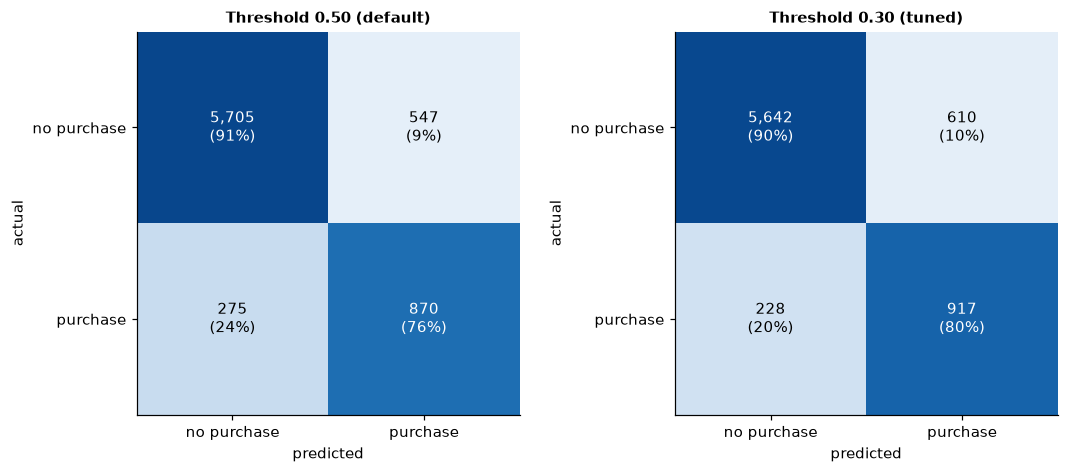

In [21]:
def plot_cm(ax, pred, title):
    cm = confusion_matrix(y_true, pred)
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.0%})", ha="center", va="center", fontsize=10,
                    color="white" if pct[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1], ["no purchase", "purchase"])
    ax.set_yticks([0, 1], ["no purchase", "purchase"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    ax.grid(False)
    ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
plot_cm(axes[0], oof_proba >= 0.5, "Threshold 0.50 (default)")
plot_cm(axes[1], oof_proba >= best_threshold, f"Threshold {best_threshold:.2f} (tuned)")
plt.tight_layout()
plt.show()

### 7. Predicted probabilities

How the out-of-fold probabilities spread for real non-buyers (teal) and real buyers (red). A model that separates the classes well pushes the teal bars left and the red bars right. The dashed line is the chosen threshold. The vertical axis is a log scale so the buyers stay visible.

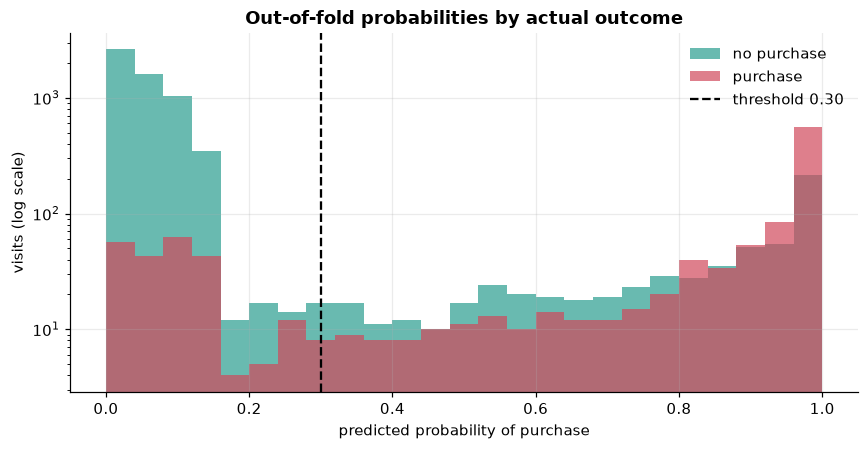

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(0, 1, 26)
ax.hist(oof_proba[y_true == 0], bins=bins, color=TEAL, alpha=0.7, label="no purchase")
ax.hist(oof_proba[y_true == 1], bins=bins, color=RED, alpha=0.7, label="purchase")
ax.axvline(best_threshold, color="black", linestyle="--", label=f"threshold {best_threshold:.2f}")
ax.set_yscale("log")
ax.set_xlabel("predicted probability of purchase")
ax.set_ylabel("visits (log scale)")
ax.set_title("Out-of-fold probabilities by actual outcome")
ax.legend()
plt.tight_layout()
plt.show()

### 8. Calibration

Do the probabilities mean what they say? Visits are sorted into 10 equal-sized groups by predicted probability. A well-calibrated model sits on the diagonal: of the visits it gives about 30%, about 30% really buy. Calibration does not affect F1 (only the ranking and the threshold do), but it shows how far the probabilities can be trusted as numbers. Below the diagonal means the model over-predicts purchases. Naive Bayes tends to push its probabilities toward 0 and 1, so most visits fall in a few groups at the extremes.

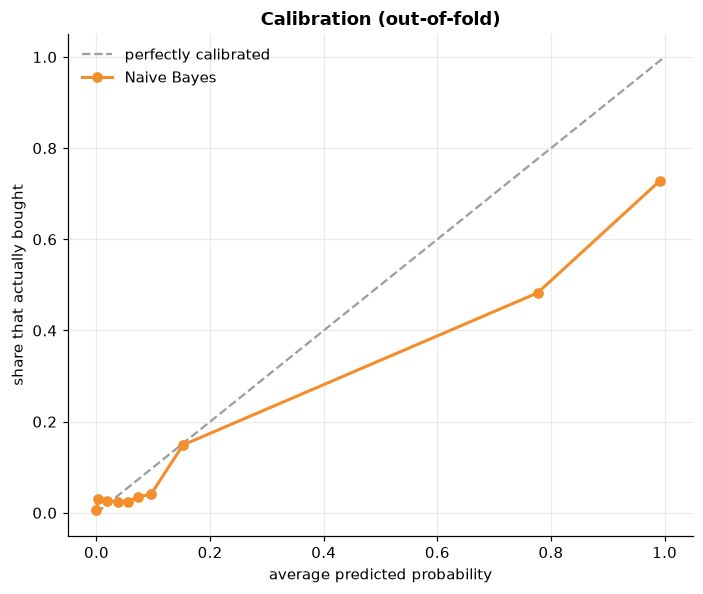

In [23]:
frac, mean = calibration_curve(y_true, oof_proba, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], "--", color=GRAY, label="perfectly calibrated")
ax.plot(mean, frac, "o-", color=MODEL_COLOR, linewidth=2, label=MODEL_LABEL)
ax.set_xlabel("average predicted probability")
ax.set_ylabel("share that actually bought")
ax.set_title("Calibration (out-of-fold)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 9. Learning curve

ROC-AUC as the training set grows (5-fold CV at each size). If the two lines are close and flat, more data will not help and the model is limited by its own simplicity. A large gap that shrinks with more data means the model would benefit from more rows.

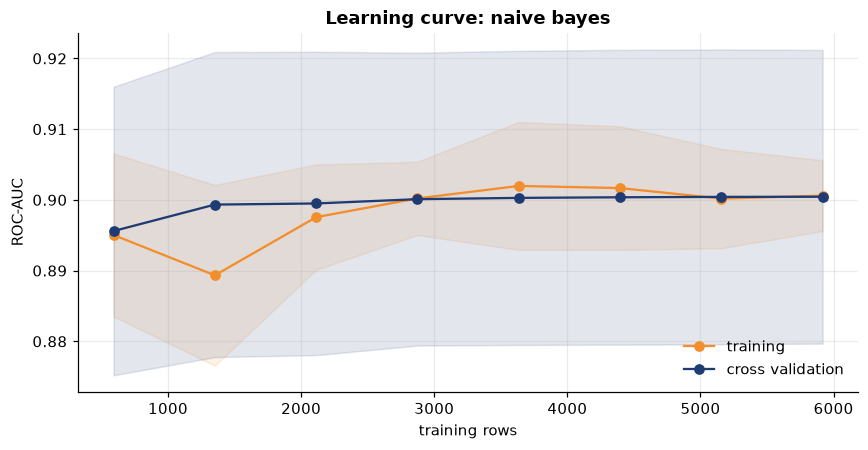

In [24]:
sizes, tr_sc, va_sc = learning_curve(clone(best_pipe), X_train, y_train, cv=cv, scoring="roc_auc",
                                     train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1,
                                     shuffle=True, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(8, 4.2))
for sc, color, name in [(tr_sc, ORANGE, "training"), (va_sc, NAVY, "cross validation")]:
    m, s = sc.mean(axis=1), sc.std(axis=1)
    ax.plot(sizes, m, "o-", color=color, label=name)
    ax.fill_between(sizes, m - s, m + s, color=color, alpha=0.12)
ax.set_xlabel("training rows")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"Learning curve: {MODEL_LABEL.lower()}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 10. Feature importance

- **Left, what the model sees**: for each of the features it kept, the average standardized value for non-buyers and for buyers. The bigger the gap, the more that feature pushes the prediction.
- **Right, permutation importance**: how much ROC-AUC drops on held-out folds when one original column is shuffled. Columns the model dropped score zero by construction.

In [25]:
def fold_perm_importance(pipe):
    imps = []
    for tr, va in cv.split(X_train, y_train):
        m = clone(pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        r = permutation_importance(m, X_train.iloc[va], y_train.iloc[va], scoring="roc_auc",
                                   n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
        imps.append(r.importances_mean)
    return pd.Series(np.mean(imps, axis=0), index=X_train.columns)

perm = fold_perm_importance(best_pipe)

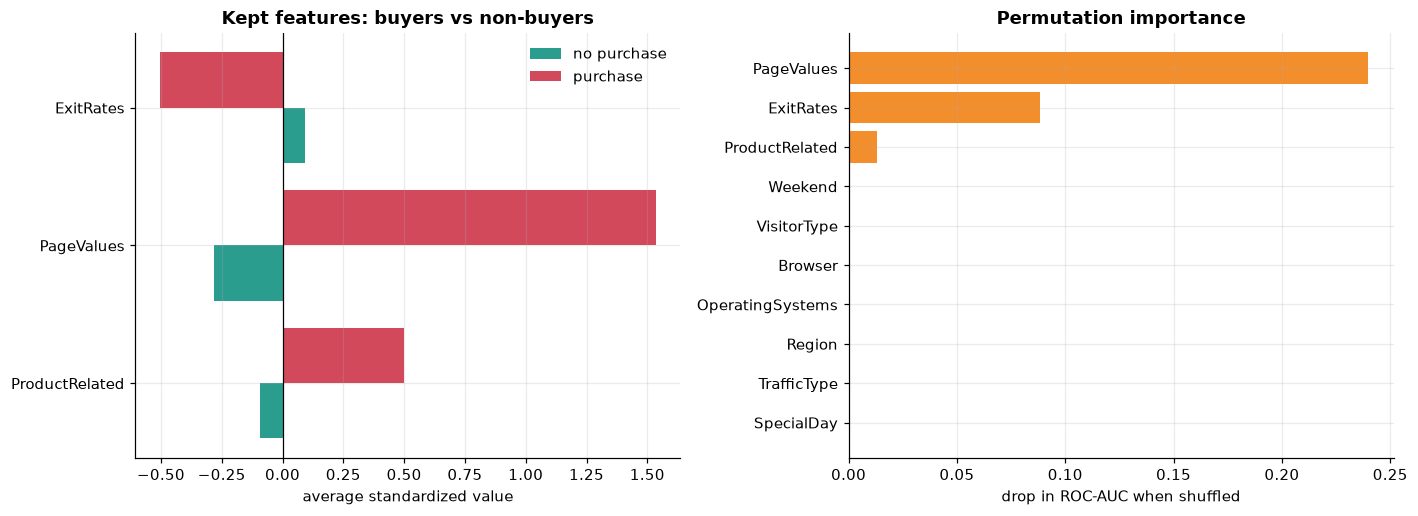

In [26]:
Zk = pd.DataFrame(nb_fit.named_steps["prep"].transform(X_train), columns=num_cols)[list(kept)]
means = Zk.groupby(y_train.to_numpy()).mean().T
means.columns = ["no purchase", "purchase"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
pos = np.arange(len(means))
ax1.barh(pos - 0.2, means["no purchase"], 0.4, color=TEAL, label="no purchase")
ax1.barh(pos + 0.2, means["purchase"], 0.4, color=RED, label="purchase")
ax1.set_yticks(pos, means.index)
ax1.axvline(0, color="black", linewidth=0.8)
ax1.set_xlabel("average standardized value")
ax1.set_title("Kept features: buyers vs non-buyers")
ax1.legend()

p = perm.sort_values().tail(10)
ax2.barh(p.index, p.values, color=ORANGE)
ax2.set_title("Permutation importance")
ax2.set_xlabel("drop in ROC-AUC when shuffled")
plt.tight_layout()
plt.show()

---
# Summary

Cross-validated scores on the training rows. The hold-out stays untouched until the team compares every model. The cut-off is a setting of the final model and has to be carried along with it.

In [27]:
s = scores_at(best_threshold)
summary = pd.DataFrame([{
    "model": "Naive Bayes (tuned)", "threshold": best_threshold,
    "f1": s["f1"], "precision": s["precision"], "recall": s["recall"],
    "roc_auc": roc_auc_score(y_true, oof_proba), "pr_auc": average_precision_score(y_true, oof_proba),
}]).set_index("model")
summary.round(3)

,threshold,f1,precision,recall,roc_auc,pr_auc
model,,,,,,
Naive Bayes (tuned),0.3,0.686,0.601,0.801,0.9,0.668


In [28]:
# for the final retrain on all of X, y: settings and threshold
final_settings = {**best_params, "threshold": best_threshold,
                  "features": f"numeric only, SelectKBest keeps: {', '.join(kept)}"}
final_settings

{'k': 3,
 'var_smoothing': 0.1,
 'threshold': 0.3,
 'features': 'numeric only, SelectKBest keeps: ProductRelated, PageValues, ExitRates'}

## Conclusions

**Result.** Tuned Naive Bayes reaches an out-of-fold F1 of 0.686 at a cut-off of 0.30 (0.680 at the default 0.5), with ROC-AUC 0.900 and PR-AUC 0.668. At that cut-off it catches about 80% of buyers and flags about 10% of non-buyers.

**What helped.**
- Removing features. Keeping all 10 numeric columns gave F1 0.50 at the default cut-off; keeping the 3 most informative (`ProductRelated`, `PageValues`, `ExitRates`) gives 0.68. The overlapping page-count and duration columns were being counted twice.
- Leaving out the one-hot columns. Including them dropped ROC-AUC to 0.70.
- `var_smoothing` made almost no difference.

**Cut-off.** Naive Bayes pushes its probabilities toward 0 and 1, so F1 is nearly flat from a cut-off of about 0.15 up to 0.8. The "best" 0.30 is just a point on that plateau, not a sharp optimum.

**Fit.** Training and CV scores are identical, so the model is not overfitting, and the learning curve is flat, so more rows would not help. It is limited by the independence assumption, not by data size. Fold-to-fold spread is larger than for the other models (ROC-AUC std 0.021).

**Caveats.**
- The cut-off and F1 above are picked and scored on the same out-of-fold predictions, so they are slightly optimistic. The hold-out score is the honest number.
- The probabilities over-predict purchases and sit mostly at the extremes (calibration chart), so they should not be read as real purchase chances.
- `PageValues` carries most of the signal, so the model depends heavily on one column.

Settings for the final retrain on all of `X, y` are in the dictionary above.